# Two-link arm: torque MPC with gravity
Run top to bottom; NumPy, SciPy, Matplotlib and IPython are sufficient. The path, geometry, collision margins, joint bounds, speed limits, horizontal alignment and animation match `two_link_mpc_toy.ipynb`.

The state is $x=(q_1,q_2,\dot q_1,\dot q_2)$; the optimized control is the **total joint torque** $\tau=(\tau_1,\tau_2)$ in N m. We use uniform links of mass 1 kg each and gravity 9.81 m/s². The simplified rigid-body model is $M(q)\ddot q+g(q)=\tau$: Coriolis, centrifugal, friction and contact forces are omitted. This is a learning model, not a full physical simulator. IK only initializes/validates the path; MPC uses FK.

Unlike velocity control, holding requires gravity-balancing torque and near-zero joint velocity. The objective therefore penalizes torque relative to gravity compensation, rather than rewarding zero total torque.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
from scipy.optimize import minimize

L = 0.8
dt = 0.10
horizon = 8
target_x = 1.5
endpoint_offset = -0.08
hover_y = 0.24
tip_speed_limit = 0.35  # m/s per Cartesian component
joint_speed_limit = 1.5
position_tolerance = 1e-3
horizontal_tolerance = 1e-4  # m, between control nodes

link_masses = np.array([1.0, 1.0])  # kg, uniform rods
gravity = 9.81
torque_limit = 30.0  # N m per joint
settle_speed_tolerance = 1e-3  # rad/s


## 1. Robot geometry
The table is $y=0$. A short fixed pedestal puts the base pivot at $(0,0.10)$, so its collision sphere can clear the table. Both links have length $L$.

$q_1\in[0,\pi]$ is the base angle, and $q_2$ is the elbow angle **relative to link 1**. The elbow uses $q_2\in[0,2\pi]$ (one full revolution). We keep this coordinate interval as joint bounds and do not wrap integrated angles. Inverse kinematics selects an elbow-up **initial pose**; subsequent poses come from integrating the state under optimized torques.

$p_1=b+L(\cos q_1,\sin q_1)$ and $p_2=p_1+L(\cos(q_1+q_2),\sin(q_1+q_2))$.

In [2]:
class TwoLinkRobot:
    def __init__(self, L=1.0, base=(0.0, 0.10)):
        self.L = float(L)
        self.base = np.asarray(base, dtype=float)

    def forward(self, q):
        q = np.asarray(q)
        a, b = q[..., 0], q[..., 0] + q[..., 1]
        elbow = self.base + self.L * np.stack([np.cos(a), np.sin(a)], axis=-1)
        tip = elbow + self.L * np.stack([np.cos(b), np.sin(b)], axis=-1)
        base = np.broadcast_to(self.base, elbow.shape)
        return np.stack([base, elbow, tip], axis=-2)

    def jacobian(self, q):
        """Tip velocity = J(q) @ joint velocity; batch dimensions supported."""
        q = np.asarray(q)
        a, b = q[..., 0], q[..., 0] + q[..., 1]
        row_x = self.L * np.stack([-np.sin(a)-np.sin(b), -np.sin(b)], axis=-1)
        row_y = self.L * np.stack([np.cos(a)+np.cos(b), np.cos(b)], axis=-1)
        return np.stack([row_x, row_y], axis=-2)

    def inverse(self, p):
        p = np.asarray(p) - self.base
        c = (np.sum(p*p, axis=-1) - 2*self.L**2) / (2*self.L**2)
        if np.any(np.abs(c) > 1 + 1e-10):
            raise ValueError("Requested initial/reference point is unreachable")
        q2_signed = -np.arccos(np.clip(c, -1.0, 1.0))
        q1 = np.arctan2(p[..., 1], p[..., 0]) - np.arctan2(
            self.L * np.sin(q2_signed),
            self.L * (1 + np.cos(q2_signed)),
        )
        q2 = q2_signed % (2 * np.pi)
        return np.stack([q1, q2], axis=-1)

robot = TwoLinkRobot(L)


## 2. Collision spheres and hard constraints
These are the 2D counterparts of `CollisionSphereModel.residuals` and `AxisAlignedBoxSDF` in [collision_spheres.py](mujoco-spostamento/catkin_ws/collision_spheres.py). A sphere appears as a circle in this plane:

- Table: $c_y-r-d_{ground}\geq0$.
- Target box: $\operatorname{SDF}_{box}(c)-r-d_{box}\geq0$.

We retain the repository's ground margin 0.02 and box margin 0.03. Each link gets overlapping circles, including its ends, with radius 0.06. All of them remain active in both phases; we are hovering, not grasping. The target is a small box resting on the table. The repository also supports other static obstacles through the same SDF residual; none are added here. Its collision-sphere model does not implement self-collision, and neither does this toy.

Constraints are checked at prediction nodes **and four intermediate samples per step**. This reduces missed collisions but is not a continuous-time collision proof. The circles define the collision geometry; link lines are only visualization.

In [3]:
sphere_radius = 0.06
d_ground, d_box = 0.02, 0.03
fractions = np.linspace(0.0, 1.0, 11)
box_half = np.array([0.055, 0.04])
box_center = np.array([target_x, box_half[1]])

def sphere_centers(q):
    joints = robot.forward(q)
    starts, ends = joints[..., :-1, :], joints[..., 1:, :]
    centers = starts[..., :, None, :] + fractions[:, None] * (
        ends - starts)[..., :, None, :]
    return centers.reshape(*joints.shape[:-2], -1, 2)

def box_sdf(p):
    delta = np.abs(np.asarray(p) - box_center) - box_half
    return np.linalg.norm(np.maximum(delta, 0), axis=-1) + np.minimum(
        np.max(delta, axis=-1), 0)

def collision_residuals(q):
    centers = sphere_centers(q)
    ground = centers[..., 1] - sphere_radius - d_ground
    target = box_sdf(centers) - sphere_radius - d_box
    return np.concatenate([ground, target], axis=-1)


## 3. Supply the trajectory
The function receives 100 evenly spaced values from 0 to 1 and returns an `(100, 2)` array of `(x, y)` points. Samples are spaced by `dt` in reference time. The default path ends 8 cm left of the target at a safe hover height. The controller starts at the first point.

Changing a path or target can make the problem infeasible. We validate the supplied path and stop on solver failures instead of animating unchecked motion.

In [4]:
def trajectory_function(s):
    start = np.array([0.50, 1.10])
    end = np.array([target_x + endpoint_offset, hover_y])
    blend = 3*s**2 - 2*s**3
    points = start + blend[:, None] * (end - start)
    points[:, 1] += 0.15 * np.sin(np.pi*s)**2
    return points

reference = np.asarray(trajectory_function(np.linspace(0, 1, 100)), dtype=float)
assert reference.shape == (100, 2) and np.isfinite(reference).all()
assert np.allclose(robot.forward(robot.inverse(reference))[:, -1], reference)
assert collision_residuals(robot.inverse(reference)).min() >= 0, "Path collides"


### Plot the trajectory samples
The line connects the supplied points; the scatter colors show their order. The endpoint is slightly offset from the target, which the second MPC will correct.

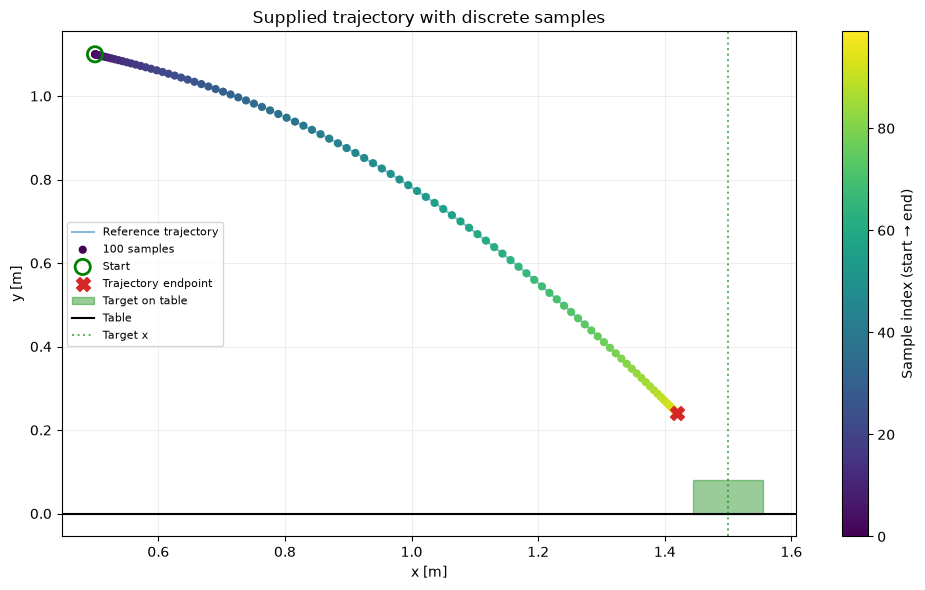

In [5]:
# Plot the supplied trajectory and each discrete sample before running MPC.
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(reference[:, 0], reference[:, 1], color="tab:blue", alpha=0.5,
        label="Reference trajectory")
samples = ax.scatter(reference[:, 0], reference[:, 1],
                     c=np.arange(len(reference)), cmap="viridis", s=24,
                     zorder=3, label=f"{len(reference)} samples")
fig.colorbar(samples, ax=ax, label="Sample index (start → end)")
ax.scatter(*reference[0], marker="o", s=120, facecolors="none",
           edgecolors="green", linewidths=2, zorder=4, label="Start")
ax.scatter(*reference[-1], marker="X", s=100, color="tab:red",
           zorder=4, label="Trajectory endpoint")
ax.add_patch(Rectangle(box_center - box_half, *(2 * box_half),
                       color="green", alpha=0.4, label="Target on table"))
ax.axhline(0, color="black", linewidth=1.5, label="Table")
ax.axvline(target_x, color="green", linestyle=":", alpha=0.6,
           label="Target x")
ax.set(xlabel="x [m]", ylabel="y [m]",
       title="Supplied trajectory with discrete samples")
ax.set_aspect("auto", adjustable="box")
ax.grid(alpha=0.2)
ax.legend(loc="best", fontsize=8)
fig.tight_layout()
plt.show()


## 4. Gravity-only dynamics and integration
For uniform rods, $l_c=L/2$, $I_i=m_iL^2/12$, and $c_2=\cos q_2$:
$$M=\begin{bmatrix}I_1+I_2+m_1l_c^2+m_2(L^2+l_c^2+2Ll_cc_2)&I_2+m_2(l_c^2+Ll_cc_2)\\I_2+m_2(l_c^2+Ll_cc_2)&I_2+m_2l_c^2\end{bmatrix}.$$
With angles measured from horizontal and upward Cartesian $y$:
$$g(q)=g_0\begin{bmatrix}(m_1l_c+m_2L)\cos q_1+m_2l_c\cos(q_1+q_2)\\m_2l_c\cos(q_1+q_2)\end{bmatrix}.$$

At each control node compute $a=M(q)^{-1}(\tau-g(q))$, then use semi-implicit Euler, matching the integration order in the original controller:
$$\dot q_{k+1}=\dot q_k+h a_k,\qquad q_{k+1}=q_k+h\dot q_{k+1}.$$
Prediction and simulation use the same discrete approximation. Between nodes, constraint checks use linear interpolation of both joint position and joint velocity. These are interpolated discrete states, not an exact continuous solution of the torque dynamics; the derivative of interpolated position need not equal interpolated velocity. No states or velocities are clipped to make constraints appear feasible. A smaller time step or a more accurate physical integrator would be needed to study continuous dynamics faithfully.


In [6]:
def mass_matrix(q):
    m1, m2 = link_masses
    lc = L / 2
    I1, I2 = link_masses * L**2 / 12
    c = np.cos(q[1])
    cross = I2 + m2 * (lc**2 + L*lc*c)
    return np.array([[I1+I2+m1*lc**2+m2*(L**2+lc**2+2*L*lc*c), cross],
                     [cross, I2+m2*lc**2]])

def gravity_torque(q):
    q = np.asarray(q)
    m1, m2 = link_masses
    distal = m2 * L/2 * np.cos(q[..., 0]+q[..., 1])
    return gravity * np.stack([(m1*L/2+m2*L)*np.cos(q[..., 0])+distal, distal], axis=-1)

def acceleration(state, torque):
    return np.linalg.solve(mass_matrix(state[:2]), torque-gravity_torque(state[:2]))

def dynamics_step(state, torque, step_dt):
    q, dq = state[:2], state[2:]
    a = acceleration(state, torque)
    return np.r_[q+step_dt*(dq+step_dt*a), dq+step_dt*a]

def rollout(x0, controls):
    states = [np.asarray(x0).copy()]
    for torque in controls:
        states.append(dynamics_step(states[-1], torque, dt))
    return np.asarray(states)

def sampled_motion(states, controls, subdivisions=5):
    states, controls = np.asarray(states), np.asarray(controls)
    a = np.array([acceleration(x, tau) for x, tau in zip(states[:-1], controls)])
    s = (dt*np.linspace(0, 1, subdivisions+1))[None, :, None]
    q = states[:-1, None, :2] + s*states[1:, None, 2:]
    dq = states[:-1, None, 2:] + s*a[:, None, :]
    return np.concatenate([q, dq], axis=-1).reshape(-1, 4)

# Basic physical checks: positive inertia and gravity-balanced rest.
for test_q in robot.inverse(reference[::10]):
    assert np.linalg.eigvalsh(mass_matrix(test_q)).min() > 0
    rest = np.r_[test_q, 0., 0.]
    assert np.allclose(dynamics_step(rest, gravity_torque(test_q), dt), rest)

## 5. MPC objective and constraints
Optimize $2N$ torques; obtain all four-component states by rollout. Preserve the Cartesian tracking weights:
$$40\sum_{j=1}^N\|f(q_j)-r_j\|^2+120\|f(q_N)-r_N\|^2+0.05\sum_{j=1}^N\|\dot q_j\|^2+0.001\sum_{j=0}^{N-1}\|\tau_j-g(q_j)\|^2.$$
The last term discourages unnecessary acceleration without introducing a gravity-induced holding offset. These velocity and torque penalties replace the old joint-velocity control penalty.

Keep the original angle, workspace, sphere-clearance and Cartesian component speed constraints. **Joint velocity remains a hard state constraint** $|\dot q_i|\leq1.5$ rad/s, checked at nodes and intermediate samples. Torque bounds are $|\tau_i|\leq30$ N m. Alignment keeps exact node height equalities and sampled 0.1 mm height tolerance. These sampled checks do not prove continuous-time safety.

In [7]:
def unpack_controls(z):
    return np.asarray(z).reshape(horizon, 2)

def mpc_objective(z, x0, refs):
    controls = unpack_controls(z)
    states = rollout(x0, controls)
    error = robot.forward(states[1:, :2])[:, -1] - refs
    effort = controls - gravity_torque(states[:-1, :2])
    return (40*np.sum(error**2) + 120*np.sum(error[-1]**2)
            + 0.05*np.sum(states[1:, 2:]**2) + 0.001*np.sum(effort**2))

def mpc_constraints(z, x0, horizontal_y=None, include_initial=False):
    controls = unpack_controls(z)
    states = rollout(x0, controls)
    samples = sampled_motion(states, controls)
    # The measured initial state is fixed, so omit its zero-derivative rows
    # from SLSQP. Check it independently with the full feasibility check.
    if not include_initial:
        samples = samples[1:]
    qs, dqs = samples[:, :2], samples[:, 2:]
    tips = robot.forward(qs)[:, -1]
    distance = np.linalg.norm(tips-robot.base, axis=1)
    tip_velocity = np.einsum('nij,nj->ni', robot.jacobian(qs), dqs)
    values = [collision_residuals(qs).ravel(), distance-0.08, 2*L-0.02-distance,
              qs[:, 0], np.pi-qs[:, 0], qs[:, 1], 2*np.pi-qs[:, 1],
              (joint_speed_limit-np.abs(dqs)).ravel(),
              (tip_speed_limit-np.abs(tip_velocity)).ravel()]
    if horizontal_y is not None:
        values.append(horizontal_tolerance-np.abs(tips[:, 1]-horizontal_y))
    return np.concatenate(values)

def horizontal_equalities(z, x0, horizontal_y):
    return robot.forward(rollout(x0, unpack_controls(z))[1:, :2])[:, -1, 1]-horizontal_y

## 6. Numerical optimization solver
SLSQP optimizes total torques using numerical derivatives. Initialize with gravity compensation; shift successful torque sequences to warm-start subsequent solves. Check solver success, finite controls and constraint feasibility before applying any command. Failures stop execution.

The first guess brakes the measured joint velocity, then balances gravity. The fixed initial state is omitted from SLSQP constraint rows because future torques cannot change it; the independent feasibility check still includes that state, with the same numerical tolerance as every other sample.

In [8]:
def solve_mpc(x0, refs, warm=None, horizontal_y=None):
    if warm is None:
        # With semi-implicit Euler, braking to zero velocity holds q exactly.
        # This also gives a feasible constant-height seed for alignment.
        seed = np.tile(gravity_torque(x0[:2]), (horizon, 1))
        seed[0] -= mass_matrix(x0[:2]) @ x0[2:] / dt
        initial = np.clip(seed, -torque_limit, torque_limit).ravel()
    else:
        initial = warm
    constraints = [{"type": "ineq", "fun": mpc_constraints,
                    "args": (x0, horizontal_y)}]
    if horizontal_y is not None:
        constraints.append({"type": "eq", "fun": horizontal_equalities,
                            "args": (x0, horizontal_y)})
    result = minimize(
        mpc_objective, initial, args=(x0, refs), method="SLSQP",
        bounds=[(-torque_limit, torque_limit)]*(2*horizon),
        constraints=constraints, options={"maxiter": 400, "ftol": 1e-9},
    )
    clearance = np.min(mpc_constraints(result.x, x0, horizontal_y, include_initial=True))
    height_error = (0.0 if horizontal_y is None else
                   np.max(np.abs(horizontal_equalities(result.x, x0, horizontal_y))))
    if (not result.success or not np.isfinite(result.x).all()
            or clearance < -1e-7 or height_error > 1e-7):
        raise RuntimeError(f"MPC failed: {result.message}; residual={clearance:.3g}; height error={height_error:.3g}")
    controls = unpack_controls(result.x)
    warm_next = np.vstack([controls[1:], controls[-1]]).ravel()
    return controls[0], warm_next, result.nit

## 7. Closed-loop simulation: follow, settle, align, hold
Follow the same 100 reference samples, then hold the endpoint until both position and joint speed settle. Record the achieved height and run horizontal alignment with the same constraints. Continue until 20 consecutive steps satisfy position and rest tolerances. Only the first optimized torque is applied each time.

### Receding-horizon torque problem
At each update solve for $U=(\tau_0,\ldots,\tau_{N-1})$ with $N=8$ and $h=0.10$ s, subject to $x_0=x_{measured}$ and the gravity-only rollout above. States are calculated from torques, not independent optimization variables. This is the torque analogue of the notebook's single-shooting formulation; the original acados code instead optimizes state/control corrections.

Apply $\tau_0^\star$, advance the four-component state with `dynamics_step`, measure the new state, shift the torque sequence and repeat. FK determines Cartesian positions and $J(q)\dot q$ determines Cartesian velocities. IK is not used to generate commands. At rest, $\tau=g(q)$, not zero.

In [9]:
q = robot.inverse(reference[0])  # IK only initializes the joint state
x = np.r_[q, 0., 0.]
p = robot.forward(q)[-1]
state_history, torque_history = [x.copy()], []
joint_history = [q.copy()]
positions, velocities, phases, iterations = [p.copy()], [], ["follow"], []
warm = None

def record_step(command, phase, nit):
    global x, q, p
    x = dynamics_step(x, command, dt)
    q = x[:2].copy()
    state_history.append(x.copy())
    torque_history.append(command.copy())
    p = robot.forward(q)[-1]
    joint_history.append(q.copy())
    positions.append(p.copy())
    velocities.append(x[2:].copy())
    phases.append(phase)
    iterations.append(nit)

for k in range(len(reference) + 120):
    indices = np.minimum(k + 1 + np.arange(horizon), len(reference)-1)
    command, warm, nit = solve_mpc(x, reference[indices], warm)
    record_step(command, "follow" if k < len(reference)-1 else "settle", nit)
    if k >= len(reference)-2 and np.linalg.norm(p-reference[-1]) < position_tolerance and np.max(np.abs(x[2:])) < settle_speed_tolerance:
        break
else:
    raise RuntimeError("Trajectory endpoint did not converge")

alignment_start = len(positions)-1
alignment_goal = np.array([target_x, p[1]])
print(f"Endpoint error: {np.linalg.norm(p-reference[-1]):.6f} m")
print(f"Measured horizontal correction: {target_x-p[0]:+.4f} m")
warm = None
hold_steps = 0
for k in range(160):
    refs = np.tile(alignment_goal, (horizon, 1))
    command, warm, nit = solve_mpc(x, refs, warm, horizontal_y=alignment_goal[1])
    record_step(command, "hold" if hold_steps else "align horizontally", nit)
    hold_steps = hold_steps + 1 if abs(p[0]-target_x) < position_tolerance and np.max(np.abs(x[2:])) < settle_speed_tolerance else 0
    if hold_steps >= 20:
        break
else:
    raise RuntimeError("Horizontal alignment did not converge")

positions = np.asarray(positions)
velocities = np.asarray(velocities)
joint_history = np.asarray(joint_history)
state_history = np.asarray(state_history)
torque_history = np.asarray(torque_history)
joint_velocities = state_history[:, 2:]  # State, not control; rad/s
checked_states = sampled_motion(state_history, torque_history, subdivisions=25)
checked_qs = checked_states[:, :2]
minimum_clearance = collision_residuals(checked_qs).min()
alignment_tips = robot.forward(sampled_motion(state_history[alignment_start:], torque_history[alignment_start:], subdivisions=25)[:, :2])[:, -1]
height_deviation = np.max(np.abs(alignment_tips[:, 1] - alignment_goal[1]))
assert minimum_clearance >= -1e-7
assert abs(positions[-1, 0]-target_x) < position_tolerance
assert np.max(np.abs(positions[alignment_start:, 1] - alignment_goal[1])) < 1e-7
assert height_deviation <= horizontal_tolerance + 1e-7
assert np.max(np.abs(joint_velocities)) <= joint_speed_limit + 1e-7
assert np.max(np.abs(checked_states[:, 2:])) <= joint_speed_limit + 1e-7
assert np.max(np.abs(torque_history)) <= torque_limit + 1e-7
checked_tip_velocities = np.einsum('nij,nj->ni', robot.jacobian(checked_qs), checked_states[:, 2:])
assert np.max(np.abs(checked_tip_velocities)) <= tip_speed_limit + 1e-7
assert np.max(np.abs(state_history[-1, 2:])) < settle_speed_tolerance
assert np.allclose(state_history[1:], [dynamics_step(xk, tau, dt) for xk, tau in zip(state_history[:-1], torque_history)])
assert np.all((checked_qs >= -1e-7) & (checked_qs <= np.array([np.pi, 2*np.pi])+1e-7))
assert np.allclose(robot.forward(joint_history)[:, -1], positions)
print(f"Final horizontal error: {positions[-1, 0]-target_x:+.6f} m")
print(f"Minimum sphere constraint residual: {minimum_clearance:.6f} m")
print(f"Simulation: {(len(positions)-1)*dt:.1f} s; {len(iterations)} MPC solves")

print(f"Maximum between-node alignment height deviation: {height_deviation:.8f} m")

Endpoint error: 0.000016 m
Measured horizontal correction: +0.0800 m
Final horizontal error: +0.000003 m
Minimum sphere constraint residual: 0.020000 m
Simulation: 13.3 s; 133 MPC solves
Maximum between-node alignment height deviation: 0.00007368 m


### Joint angles versus time
These are the **actual simulated** joint angles. $q_1$ is measured from the horizontal; $q_2$ is the elbow angle **relative to link 1**, not the absolute orientation $q_1+q_2$ of link 2.

For display, $q_2$ is expressed in $[0,2\pi)$: for example, $-\pi/2$ and $3\pi/2$ describe the same relative angle. This conversion does not change the simulation. A crossing of the $0/2\pi$ boundary would appear as a wrap in this plot. The dashed line marks the start of horizontal alignment.

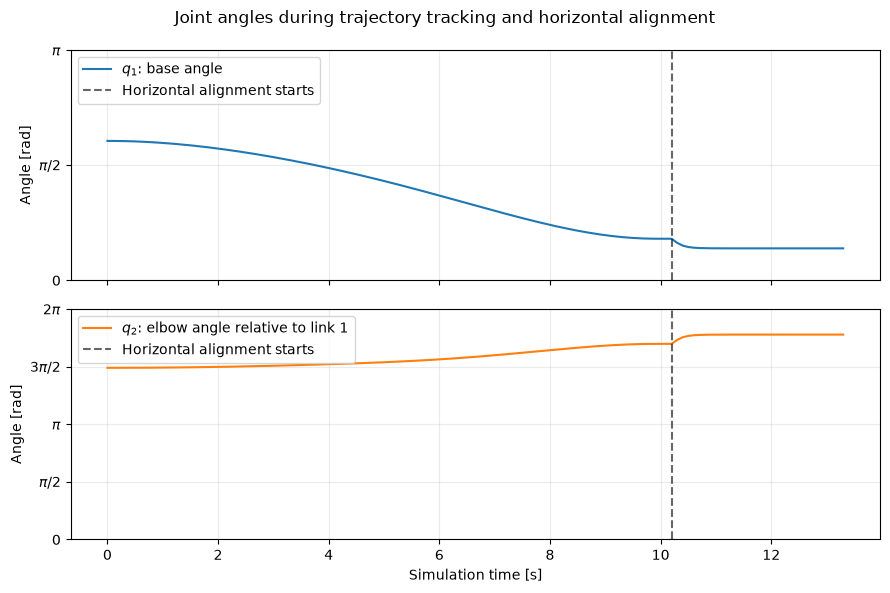

In [10]:
angle_times = np.arange(len(joint_history)) * dt
q1_plot = joint_history[:, 0]
q2_plot = np.mod(joint_history[:, 1], 2 * np.pi)

fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
axes[0].plot(angle_times, q1_plot, color="tab:blue", label=r"$q_1$: base angle")
axes[1].plot(angle_times, q2_plot, color="tab:orange",
             label=r"$q_2$: elbow angle relative to link 1")
axes[0].set_yticks([0, np.pi/2, np.pi], ["0", r"$\pi/2$", r"$\pi$"])
axes[1].set_yticks([0, np.pi/2, np.pi, 3*np.pi/2, 2*np.pi],
                  ["0", r"$\pi/2$", r"$\pi$", r"$3\pi/2$", r"$2\pi$"])
for ax in axes:
    ax.axvline(angle_times[alignment_start], color="black", linestyle="--",
               alpha=0.6, label="Horizontal alignment starts")
    ax.set_ylabel("Angle [rad]")
    ax.grid(alpha=0.25)
    ax.legend(loc="best")
axes[1].set_xlabel("Simulation time [s]")
fig.suptitle("Joint angles during trajectory tracking and horizontal alignment")
fig.tight_layout()
plt.show()


## 8. Diagnostics
Position, joint angles and sphere clearance use the same plots as the velocity notebook. Additional plots distinguish joint velocities (states) from applied torques (controls), with hard limits and the gravity torque for comparison.

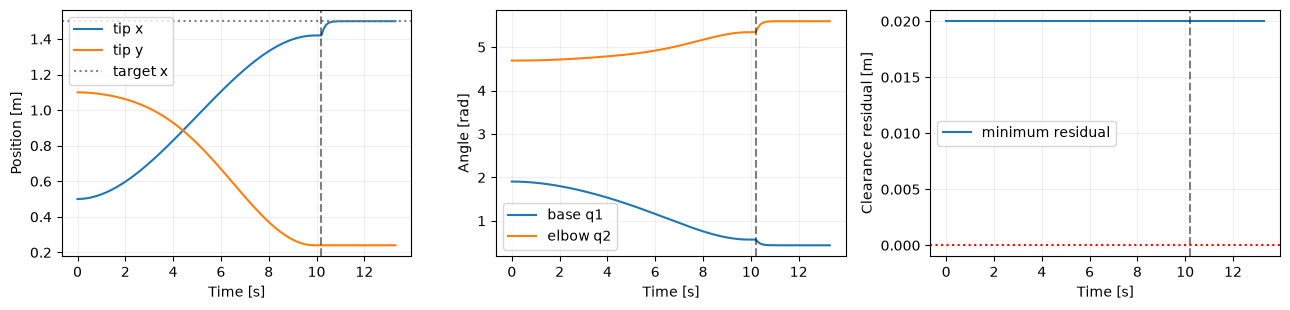

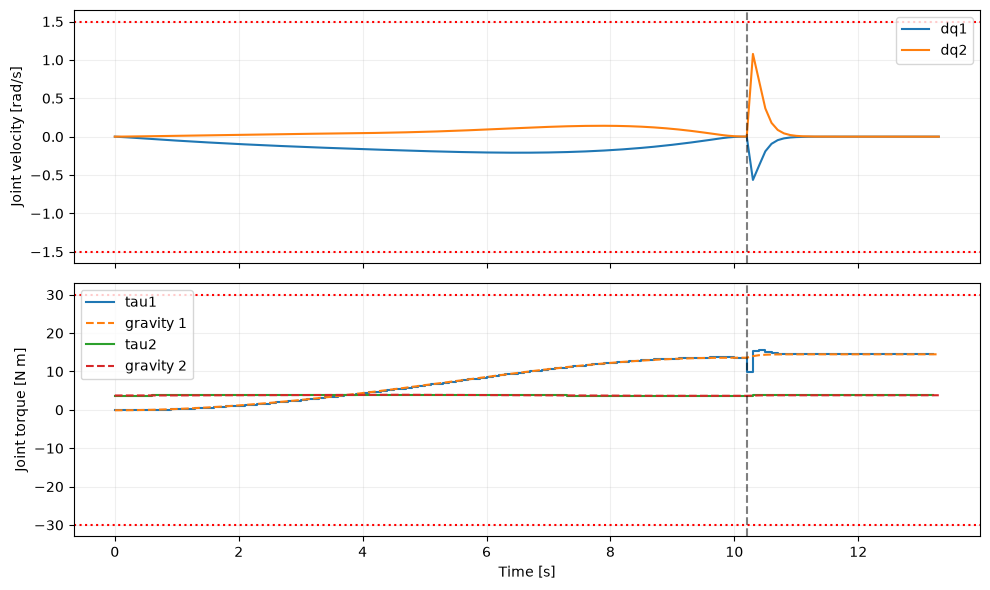

In [11]:
times = np.arange(len(positions))*dt
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
axes[0].plot(times, positions[:, 0], label="tip x")
axes[0].plot(times, positions[:, 1], label="tip y")
axes[0].axhline(target_x, color="gray", ls=":", label="target x")
axes[0].set_ylabel("Position [m]")
axes[1].plot(times, joint_history[:, 0], label="base q1")
axes[1].plot(times, joint_history[:, 1], label="elbow q2")
axes[1].set_ylabel("Angle [rad]")
axes[2].plot(times, collision_residuals(joint_history).min(axis=1), label="minimum residual")
axes[2].axhline(0, color="red", ls=":")
axes[2].set_ylabel("Clearance residual [m]")
for ax in axes:
    ax.axvline(times[alignment_start], color="black", ls="--", alpha=.5)
    ax.set_xlabel("Time [s]")
    ax.legend()
    ax.grid(alpha=.2)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for j in range(2):
    axes[0].plot(times, joint_velocities[:, j], label=f"dq{j+1}")
    axes[1].step(times[:-1], torque_history[:, j], where="post", label=f"tau{j+1}")
    axes[1].plot(times, gravity_torque(joint_history)[:, j], "--", label=f"gravity {j+1}")
for sign in [-1, 1]:
    axes[0].axhline(sign*joint_speed_limit, color="red", ls=":")
    axes[1].axhline(sign*torque_limit, color="red", ls=":")
axes[0].set_ylabel("Joint velocity [rad/s]")
axes[1].set_ylabel("Joint torque [N m]")
axes[1].set_xlabel("Time [s]")
for ax in axes:
    ax.axvline(times[alignment_start], color="black", ls="--", alpha=.5)
    ax.grid(alpha=.2)
    ax.legend()
fig.tight_layout()
plt.show()


## 9. Slow animation with every collision sphere
Blue and orange circles move with their respective links. Their outlines are the **actual sphere radii**; the safety margins are additional distances used by the constraints. Red circles would indicate a violated constraint. The dashed green line is the horizontal correction at the achieved height.

Playback is slowed to 40% of simulation speed (250 ms per 100 ms simulation step). Use the player controls to pause or step through frames. Reduce `playback_interval_ms` for faster playback.

In [12]:
playback_interval_ms = 250
plt.rcParams["animation.embed_limit"] = 60
fig, ax = plt.subplots(figsize=(8, 6))
ax.set_aspect("equal")
ax.set_xlim(-0.30, 2.10)
ax.set_ylim(-0.12, 2.15)
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")
ax.axhline(0, color="black", lw=2, label="table")
ax.plot([0, 0], [0, robot.base[1]], color="gray", lw=8)
ax.add_patch(Rectangle(box_center-box_half, *(2*box_half), color="green", alpha=.55))
ax.plot(reference[:, 0], reference[:, 1], "--", color="gray", label="supplied path")
ax.plot([positions[alignment_start, 0], target_x], [alignment_goal[1]]*2,
        "g--", label="horizontal correction")
ax.plot(*reference[-1], "kx", label="path endpoint")
ax.plot(*alignment_goal, "g*", ms=12, label="final hover goal")
arm_line, = ax.plot([], [], "o-", color="black", lw=3)
trail, = ax.plot([], [], color="purple", alpha=.6, label="actual tip path")
circles = []
for j in range(2*len(fractions)):
    circle = Circle((0, 0), sphere_radius, fill=False,
                    edgecolor="tab:blue" if j < len(fractions) else "tab:orange", alpha=.65)
    ax.add_patch(circle)
    circles.append(circle)
status = ax.text(.02, .97, "", transform=ax.transAxes, va="top")
ax.legend(loc="upper right", fontsize=8)

def animate(frame):
    q = joint_history[frame]
    joints = robot.forward(q)
    arm_line.set_data(joints[:, 0], joints[:, 1])
    trail.set_data(positions[:frame+1, 0], positions[:frame+1, 1])
    centers = sphere_centers(q)
    residual = collision_residuals(q).reshape(2, -1).min(axis=0)
    for j, circle in enumerate(circles):
        circle.center = centers[j]
        circle.set_edgecolor("red" if residual[j] < -1e-7 else
                             ("tab:blue" if j < len(fractions) else "tab:orange"))
    status.set_text(f"t = {times[frame]:.1f} s | {phases[frame]}\n"
                    f"x error = {positions[frame, 0]-target_x:+.4f} m")
    return [arm_line, trail, status, *circles]

animation = FuncAnimation(fig, animate, frames=len(positions),
                          interval=playback_interval_ms, blit=False, repeat=True)
plt.close(fig)
display(HTML(animation.to_jshtml()))
